# Identifying Continuous Dose-Response Curves from Recourse Explanations

**A walkthrough of the recourse-based CADR estimation method on synthetic data.**

This notebook accompanies the paper *Identifying Continuous Dose-Response Curves from Recourse Explanations.* It reproduces the synthetic experiments end-to-end:

1. **Data generation.** A structural causal model (SCM) with continuous treatment, a binary threshold-crossing outcome, and treatment-side recourses generated for every negative-outcome unit.
2. **Identification.** A Lynden–Bell-style inversion that recovers the conditional dose-response surface from the truncated boundary distribution induced by recourses.
3. **Methodology.** An auxiliary loss that supervises any continuous-treatment estimator with LB-reweighted threshold-crossing pseudo-labels.
4. **Evaluation.** A grid of six neural dose-response estimators (TARNet, DRNet, VCNet, TransTEE, ADMIT, DRVAE) compared in three variants (baseline, +Recourse, +Lynden–Bell) on MISE, AMSE, and a decision-policy regret metric.

**Notation.** Throughout the notebook we use the paper's notation:

- $\mathbf{X} \in \mathbb{R}^{d_x}$: pre-treatment confounders.
- $T \in [T_{\min}, T_{\max}]$: continuous treatment.
- $Y \in \{0,1\}$: binary outcome, generated as $Y = \mathbf{1}\{T \geq g(\mathbf{x}, u_Y)\}$.
- $B = g(\mathbf{X}, U_Y)$: per-unit boundary (latent threshold).
- $b_i = t_i + \delta_{t,i}$: observed boundary for unit $i$, revealed by treatment-side recourse.
- $R \in \{0,1\}$: latent responder indicator; $R = 1$ if some $t \in \mathcal{T}$ would yield $Y = 1$.
- $\mathrm{TR}_i = \mathbf{1}\{Y_i = 0 \wedge R_i = 1\}$: observable treatment-side-recourse flag.
- $\mu(\mathbf{x}, t) = \mathbb{E}[Y(t) \mid \mathbf{X} = \mathbf{x}]$: the CADR target.

**Reading order.** Each section opens with a short orientation paragraph and a recap of what the cell does. You can run cells top-to-bottom; the synthetic data is regenerated each time and intermediate state is held in memory only.


In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from scipy.special import expit
from scipy.stats import norm, gumbel_r
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler
from typing import Dict, Callable
import matplotlib.pyplot as plt

torch.set_num_threads(4)

# Configuration
D_X = 5
N_OBS = 3000
N_VAL = 1500
N_RCT_VAL = 500
N_TEST = 3000
N_SEEDS = 1
T_MIN, T_MAX = -3.0, 3.0
OBS_T_MAX = 0.0
T_GRID = np.linspace(T_MIN, T_MAX, 61)
N_EPOCHS = 1000
PATIENCE = 100
EVAL_EVERY = 10
# Default lambda (fallback for any model not listed in LAMBDA_PER_MODEL).
LAM = 0.3

# Per-model lambda overrides. Set to a float to override LAM for that
# (model_name, variant_kind) pair; omit a key to use LAM. Keys:
#   - parametric baselines: 'MLP-regressor', 'TARNet', 'DRNet', 'VCNet',
#                           'TransTEE', 'ADMIT', 'DRVAE'
#   - standalone estimators: 'LB-estimator', 'Unweighted-estimator'
# Variant kinds for parametric baselines: 'LB' (LB-weighted recourse),
#                                         'unweighted' (uniform-weight recourse).
# The 'baseline' variant has lam=0.0 by construction and is unaffected.
# Standalone estimators have a single variant kind (no variant suffix needed).
LAMBDA_PER_MODEL = {
    # Examples -- override or remove as desired:
    ('TARNet',   'LB'):           1.0,
    ('TARNet',   'unweighted'):   1.0,
    # ('DRNet',    'LB'):         0.3,
    # ('VCNet',    'LB'):         0.1,
    ('TransTEE', 'unweighted'):   0.05,
    ('TransTEE', 'LB'):           0.05,
    # ('ADMIT',    'LB'):         0.3,
    # ('DRVAE',    'LB'):         0.3,
    # ('LB-estimator',         None): 1.0,
    # ('Unweighted-estimator', None): 1.0,
}

CF_SAMPLES_PER_UNIT = 4
PRESAMPLE_CF = True

G_SHIFT = -2.0

# *** Threshold-noise distribution. ***
# 'logistic': mu(x, t) is logistic in t (logit-linear in t). VCNet's polynomial basis matches this trivially.
# 'gumbel':   mu(x, t) is Gumbel CDF in t. Asymmetric -- slow rise lower, sharp saturation upper.
U_Y_DIST = 'gumbel'
U_Y_SCALE = 2.0

REPORT_IN_OUT_SPLIT = False

# *** Nuisance estimation mode for the LB weights. ***
# 'estimated':  P(Y=0|x) via logistic regression on x; F_T(b|x) via Gaussian-with-linear-mean
#               fit on the observational sample. Mildly misspecified under Gumbel u_Y -- closer
#               to what a real-data practitioner would do.
# 'analytical': P(Y=0|x) via numerical integration of the known SCM (Gumbel-noise convolution
#               with the truncated-Gaussian F_T); F_T(b|x) via the known truncated-Gaussian
#               with the true BETA_T and the noise std used in sample_dataset. Oracle nuisances.
NUISANCE_MODE = 'analytical'

# *** Treatment-noise std used by sample_dataset (rejection sampling around X @ BETA_T). ***
# Hardcoded in sample_dataset as 0.8; exposed here so the analytical F_T can use the truth.
SIGMA_T = 0.8

np.random.seed(0)
BETA_G = np.random.randn(D_X) * 0.8
BETA_T = np.random.randn(D_X) * 0.3
GAMMA_G = np.random.randn(D_X, D_X) * 0.15
GAMMA_G = (GAMMA_G + GAMMA_G.T) / 2

## 1. Synthetic data generation

We instantiate a threshold-crossing SCM where $\mu(\mathbf{x}, t)$ has a closed form and the recourse boundaries are known exactly. This gives us ground truth to evaluate estimator error.

### Structural equations

$$
\mathbf{X} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}_{d_x}), \qquad
T \mid \mathbf{x} \sim \mathcal{N}(\mathbf{x}^{\top} \boldsymbol{\beta}_T, \sigma_T^2) \text{ truncated to } [T_{\min}, T_{\max}^{\mathrm{obs}}],
$$

$$
Y = \mathbf{1}\{T \geq g(\mathbf{x}, u_Y)\}, \qquad
g(\mathbf{x}, u_Y) = \boldsymbol{\beta}_g^{\top} \mathbf{x} + \mathbf{x}^{\top} \boldsymbol{\Gamma}_g \mathbf{x} + c_g + u_Y.
$$

The observable treatment range $[T_{\min}, T_{\max}^{\mathrm{obs}}]$ is strictly narrower than the evaluation range $[T_{\min}, T_{\max}]$, so $\mathrm{supp}(B \mid \mathbf{x})$ extends beyond $\mathrm{supp}(T \mid \mathbf{x})$. This is the regime where classical positivity (A1) fails but recourse-positivity (A1$'$) can hold.

### Recourse construction

For each $\{Y_i = 0\}$ unit, the boundary $b_i = g(\mathbf{x}_i, u_{Y,i})$ is treated as a boundary-faithful treatment-only recourse:
$\boldsymbol{\delta}_i = (\mathbf{0}, b_i - t_i)$, so $\mathrm{TR}_i = 1$.
This sidesteps optimizer-fidelity questions and isolates the LB inversion as the object under study.

### Lynden–Bell weights

The per-unit LB weight is
$$
w(\mathbf{x}, b) = \frac{P(\mathrm{TR} = 1 \mid \mathbf{x}, R = 1)}{F_{T \mid \mathbf{x}}(b^-)},
$$

which requires two nuisance components: a probability classifier and a conditional treatment CDF. We provide both an *analytical* path (using the known SCM parameters; used in this notebook) and an *estimated* path (using fitted nuisances) for honesty in real data scenarios.


In [2]:
# ----------------------------------------------------------------
# Helpers: noise CDF and noise sampling depending on U_Y_DIST.
# Both 'logistic' and 'gumbel' preserve the threshold-crossing structure
#   Y = 1{T >= g(x, u_Y)} with g(x, u_Y) = m(x) + u_Y,
# so true_g is unchanged across distributions. Only mu's t-shape changes,
# because mu(x, t) = P(g(x, U_Y) <= t) = F_noise(t - m(x)).
# ----------------------------------------------------------------
def _noise_cdf(z: np.ndarray) -> np.ndarray:
    if U_Y_DIST == 'logistic':
        return expit(z / 1.0)
    if U_Y_DIST == 'gumbel':
        return gumbel_r.cdf(z, loc=0, scale=U_Y_SCALE)
    raise ValueError(f'unknown U_Y_DIST: {U_Y_DIST}')

def _sample_uY(rng: np.random.Generator, n: int) -> np.ndarray:
    if U_Y_DIST == 'logistic':
        return rng.logistic(0, 1, size=n)
    if U_Y_DIST == 'gumbel':
        return rng.gumbel(0, U_Y_SCALE, size=n)
    raise ValueError(f'unknown U_Y_DIST: {U_Y_DIST}')

def _m(X: np.ndarray) -> np.ndarray:
    """Deterministic threshold offset: m(x) = x'BETA_G + x'GAMMA_G x + G_SHIFT."""
    return X @ BETA_G + np.einsum('ni,ij,nj->n', X, GAMMA_G, X) + G_SHIFT


def true_mu(X: np.ndarray, t: float) -> np.ndarray:
    return _noise_cdf(t - _m(X))

def true_g(X: np.ndarray, u_Y: np.ndarray) -> np.ndarray:
    return _m(X) + u_Y

def sample_dataset(n: int, seed: int, regime: str) -> Dict:
    rng = np.random.default_rng(seed)
    X = rng.normal(0, 1, size=(n, D_X))
    u_Y = _sample_uY(rng, n)
    if regime == 'obs':
        T = np.empty(n)
        for i in range(n):
            while True:
                tc = X[i] @ BETA_T + rng.normal(0, SIGMA_T)
                if T_MIN <= tc <= OBS_T_MAX:
                    T[i] = tc; break
    elif regime == 'rct':
        T = rng.uniform(T_MIN, T_MAX, size=n)
    else:
        raise ValueError(regime)
    g_vals = true_g(X, u_Y)
    Y = (T >= g_vals).astype(int)
    b = g_vals.copy()
    R = (Y == 0).astype(int)
    return {'X': X, 'T': T, 'Y': Y, 'u_Y': u_Y, 'b': b, 'delta_t': b - T, 'R': R}


# ----------------------------------------------------------------
# F_T(b | x) -- two flavors.
# ----------------------------------------------------------------
def fit_FT_gaussian(X: np.ndarray, T: np.ndarray) -> Callable:
    """ESTIMATED F_T(b|x): linear regression for mean, residual std for sigma,
    truncated to [T_MIN, OBS_T_MAX]."""
    reg = LinearRegression().fit(X, T)
    residuals = T - reg.predict(X)
    sigma = max(residuals.std(), 0.1)
    def FT_cond(b: np.ndarray, X_q: np.ndarray) -> np.ndarray:
        mu = reg.predict(X_q)
        F_lo = norm.cdf(T_MIN, loc=mu, scale=sigma)
        F_hi = norm.cdf(OBS_T_MAX, loc=mu, scale=sigma)
        total = np.maximum(F_hi - F_lo, 1e-6)
        b_c = np.minimum(b, OBS_T_MAX)
        F_b = norm.cdf(b_c, loc=mu, scale=sigma)
        adj = (F_b - F_lo) / total
        adj = np.where(b < T_MIN, 0.0, adj)
        return np.clip(adj, 1e-6, 1 - 1e-6)
    return FT_cond

def fit_FT_analytical() -> Callable:
    """ANALYTICAL F_T(b|x) using the KNOWN DGP parameters: T|x ~ N(x'BETA_T, SIGMA_T^2)
    truncated to [T_MIN, OBS_T_MAX]. Same functional form as fit_FT_gaussian, but the
    parameters are the truth, not estimates."""
    def FT_cond(b: np.ndarray, X_q: np.ndarray) -> np.ndarray:
        mu = X_q @ BETA_T
        sigma = SIGMA_T
        F_lo = norm.cdf(T_MIN, loc=mu, scale=sigma)
        F_hi = norm.cdf(OBS_T_MAX, loc=mu, scale=sigma)
        total = np.maximum(F_hi - F_lo, 1e-6)
        b_c = np.minimum(b, OBS_T_MAX)
        F_b = norm.cdf(b_c, loc=mu, scale=sigma)
        adj = (F_b - F_lo) / total
        adj = np.where(b < T_MIN, 0.0, adj)
        return np.clip(adj, 1e-6, 1 - 1e-6)
    return FT_cond


# ----------------------------------------------------------------
# P(Y=0 | x) -- two flavors.
# ----------------------------------------------------------------
def p_y0_analytical(X: np.ndarray, n_grid: int = 200) -> np.ndarray:
    """Compute P(Y=0|x) under the KNOWN SCM by numerical integration over u_Y.

    P(Y=0|x) = E_{u_Y}[ F_T(m(x) + u_Y | x) ]

    where F_T is the truncated-Gaussian CDF using the true BETA_T, SIGMA_T, [T_MIN, OBS_T_MAX].
    Numerical integration uses a fixed grid of u_Y values; for U_Y_DIST='gumbel' we discretize
    the Gumbel(0, U_Y_SCALE) at evenly-spaced quantiles -> exact in expectation under refinement.
    """
    FT = fit_FT_analytical()
    if U_Y_DIST == 'gumbel':
        # Quantile-based discretization of Gumbel(0, U_Y_SCALE)
        qs = np.linspace(1e-3, 1 - 1e-3, n_grid)
        u_grid = gumbel_r.ppf(qs, loc=0, scale=U_Y_SCALE)
    elif U_Y_DIST == 'logistic':
        qs = np.linspace(1e-3, 1 - 1e-3, n_grid)
        u_grid = np.log(qs / (1 - qs))   # logistic ppf with scale 1
    else:
        raise ValueError(f'unknown U_Y_DIST: {U_Y_DIST}')
    # E_u[F_T(m(x) + u | x)] approximated by mean over equally-weighted quantiles
    m_vals = _m(X)
    out = np.zeros(len(X))
    for u in u_grid:
        b_at_u = m_vals + u
        out += FT(b_at_u, X)
    out /= n_grid
    return out


# ----------------------------------------------------------------
# LB weights with toggleable nuisance source.
# ----------------------------------------------------------------
def compute_lynden_bell_weights(X_r, b_r, X_all, y_all, T_all,
                                 clip_q=0.95, nuisance_mode=None):
    """Compute LB weights w_i = P(Y=0|x_i) / F_T(b_i|x_i).

    nuisance_mode:
      None       -> use module-level NUISANCE_MODE config (default 'estimated').
      'estimated' -> sklearn LogisticRegression for P(Y=0|x), Gaussian-fit F_T.
      'analytical' -> known-SCM analytical P(Y=0|x) and F_T.

    clip_q controls upper-tail clipping of the resulting weights. Set to 1.0 to disable.
    Final step: normalize to mean 1.
    """
    mode = nuisance_mode if nuisance_mode is not None else NUISANCE_MODE
    if mode == 'estimated':
        FT = fit_FT_gaussian(X_all, T_all)
        clf = LogisticRegression(max_iter=500).fit(X_all, y_all)
        pY0 = clf.predict_proba(X_r)[:, 0]
    elif mode == 'analytical':
        FT = fit_FT_analytical()
        pY0 = p_y0_analytical(X_r)
    else:
        raise ValueError(f'unknown nuisance_mode: {mode}')
    FT_at_b = FT(b_r, X_r)
    #w = 1 / np.maximum(FT_at_b, 1e-3)
    w = pY0 / np.maximum(FT_at_b, 1e-3)
    if clip_q < 1.0:
        cap = np.quantile(w, clip_q)
        w = np.clip(w, 0, cap)
    return w / w.mean()

### 1.1 Data visualization

We sample one obs split and produce two diagnostic views:

1. **Treatment marginal vs. boundary marginal.** Confirms that the truncation $[T_{\min}, T_{\max}^{\mathrm{obs}}]$ on $T$ leaves the boundary support extending beyond it — this is the regime where recourse-positivity activates.
2. **LB weights at a fixed evaluation point.** Histogram of $\hat w_i$ for one $\mathbf{x}_0$ slice; the clip-and-renormalize step keeps the tail bounded.


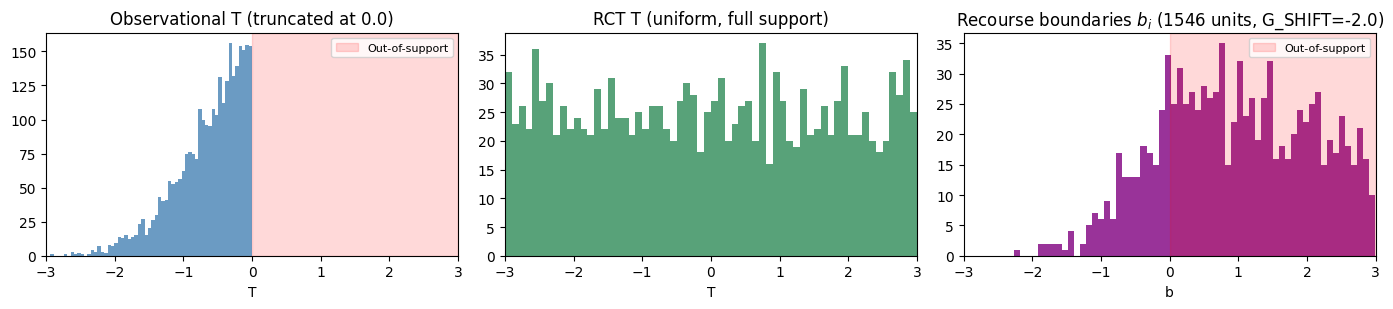

Boundaries above OBS_T_MAX (positivity-violating region): 0.866
Boundaries inside obs support [T_MIN, OBS_T_MAX]:           0.134
Boundaries below T_MIN:                                     0.000


In [3]:
obs_diag = sample_dataset(N_OBS, seed=1, regime='obs')
rct_diag = sample_dataset(N_VAL, seed=2, regime='rct')
Rm_diag = obs_diag['R'] == 1
b_diag = obs_diag['b'][Rm_diag]
b_clip = b_diag[(b_diag >= T_MIN) & (b_diag <= T_MAX)]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
axes[0].hist(obs_diag['T'], bins=60, color='steelblue', alpha=0.8)
axes[0].axvspan(OBS_T_MAX, T_MAX, color='red', alpha=0.15, label='Out-of-support')
axes[0].set_title(f'Observational T (truncated at {OBS_T_MAX})')
axes[0].set_xlabel('T'); axes[0].set_xlim(T_MIN, T_MAX); axes[0].legend(fontsize=8)

axes[1].hist(rct_diag['T'], bins=60, color='seagreen', alpha=0.8)
axes[1].set_title('RCT T (uniform, full support)')
axes[1].set_xlabel('T'); axes[1].set_xlim(T_MIN, T_MAX)

axes[2].hist(b_clip, bins=60, color='purple', alpha=0.8)
axes[2].axvspan(OBS_T_MAX, T_MAX, color='red', alpha=0.15, label='Out-of-support')
axes[2].set_title(f'Recourse boundaries $b_i$ ({Rm_diag.sum()} units, G_SHIFT={G_SHIFT})')
axes[2].set_xlabel('b'); axes[2].set_xlim(T_MIN, T_MAX); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f'Boundaries above OBS_T_MAX (positivity-violating region): {(b_diag > OBS_T_MAX).mean():.3f}')
print(f'Boundaries inside obs support [T_MIN, OBS_T_MAX]:           {((b_diag >= T_MIN) & (b_diag <= OBS_T_MAX)).mean():.3f}')
print(f'Boundaries below T_MIN:                                     {(b_diag < T_MIN).mean():.3f}')

## 2. Dose-response baselines

We compare six neural dose-response architectures, each producing $\hat\mu_\theta(\mathbf{x}, t)$. In Section 4 we run each in three variants:

- **Baseline.** Trained on factual outcomes only (cross-entropy on $(t_i, y_i)$).
- **+ Recourse.** Adds the auxiliary recourse loss with *unweighted* threshold-crossing pseudo-labels.
- **+ Lynden–Bell.** Adds the auxiliary loss with LB-reweighted pseudo-labels.

The auxiliary loss applied to a model $\hat\mu_\theta$ is:

$$
\mathcal{L}_{\text{Rec}}(\theta)
=
\frac{1}{|\mathcal{I}_{\text{Rec}}|\, k}
\sum_{i \in \mathcal{I}_{\text{Rec}}} \sum_{j=1}^{k}
\omega_i \cdot \ell\!\left(\hat\mu_\theta(\mathbf{x}_i, t_j^{\text{cf}}),\, y_{ij}^{\text{cf}}\right),
$$

with $\omega_i = \hat w_i$ (LB-weighted) or $\omega_i = 1$ (unweighted), and pseudo-labels $y_{ij}^{\text{cf}} = \mathbf{1}\{t_j^{\text{cf}} \geq b_i\}$ for $\mathrm{TR}_i = 1$ units. The total loss is $\mathcal{L}_{\text{Base}} + \lambda \mathcal{L}_{\text{Rec}}$.

### 2.1 MLP-regressor (standalone reference)

A small MLP trained *only* on the auxiliary loss (with `use_obs=False`), no observational supervision. Serves as a "what does the recourse signal alone give you?" reference.


In [4]:
class MLPRegressor(nn.Module):
    """Simple reference: MLP on [X, T] -> logit."""
    def __init__(self, d_x: int = D_X, hidden: int = 5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_x + 1, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 1),
        )
    def forward(self, x, t):
        return self.net(torch.cat([x, t.unsqueeze(-1)], dim=-1)).squeeze(-1)
    def predict_mu(self, x, t):
        return torch.sigmoid(self.forward(x, t))
    def aux_loss(self, x, t):
        return torch.zeros((), device=x.device)

### 2.2 DRNet (Schwab et al., 2020)

Discrete-bin treatment regression. The treatment domain $[T_{\min}, T_{\max}]$ is partitioned into bins, each with its own head; predictions interpolate between bin centroids. Tends to be the strongest performer on tabular CADR benchmarks but is sensitive to bin placement near sparse-support regions.


In [5]:
class DRNet(nn.Module):
    """Shared trunk phi(X) + K treatment-conditional bin heads."""
    def __init__(self, d_x: int = D_X, n_bins: int = 4, rep_dim: int = 32,
                 head_hidden: int = 32, t_min: float = T_MIN, t_max: float = T_MAX):
        super().__init__()
        self.n_bins = n_bins
        self.t_min, self.t_max = t_min, t_max
        # Shared covariate trunk (core DRNet component)
        self.trunk = nn.Sequential(
            nn.Linear(d_x, rep_dim), nn.ReLU(),
            nn.Linear(rep_dim, rep_dim), nn.ReLU(),
        )
        # Treatment-conditional heads operate on the shared representation
        self.heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(rep_dim, head_hidden), nn.ReLU(),
                nn.Linear(head_hidden, 1),
            ) for _ in range(n_bins)
        ])
    def _bin_idx(self, t):
        frac = (t - self.t_min) / (self.t_max - self.t_min)
        return torch.clamp((frac * self.n_bins).long(), 0, self.n_bins - 1)
    def forward(self, x, t):
        phi = self.trunk(x)
        bins = self._bin_idx(t)
        all_out = torch.stack([h(phi) for h in self.heads], dim=1).squeeze(-1)  # (N, K)
        return all_out.gather(1, bins.unsqueeze(1)).squeeze(1)
    def predict_mu(self, x, t):
        return torch.sigmoid(self.forward(x, t))
    def aux_loss(self, x, t):
        return torch.zeros((), device=x.device)

### 2.3 TARNet (Shalit et al., 2017)

Two-headed treatment-arm regression. Originally a binary-treatment method; here we adapt it by binarizing $T$ at the midpoint of $[T_{\min}, T_{\max}]$ (so its dose-response curve is a step function with two heads). Included as a representation-learning baseline; its limited expressiveness on continuous treatments is intentional.


In [6]:
class TARNet(nn.Module):
    """Binarized TARNet: shared trunk + two heads for T below/above midpoint."""
    def __init__(self, d_x: int = D_X, rep_dim: int = 32, head_hidden: int = 32,
                 t_min: float = T_MIN, t_max: float = T_MAX):
        super().__init__()
        self.t_min, self.t_max = t_min, t_max
        self.t_mid = 0.5 * (t_min + t_max)
        # Shared covariate trunk
        self.trunk = nn.Sequential(
            nn.Linear(d_x, rep_dim), nn.ReLU(),
            nn.Linear(rep_dim, rep_dim), nn.ReLU(),
        )
        # Two treatment-specific heads (low/high)
        self.heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(rep_dim, head_hidden), nn.ReLU(),
                nn.Linear(head_hidden, 1),
            ) for _ in range(2)
        ])
    def forward(self, x, t):
        phi = self.trunk(x)
        # bin 0 = T <= midpoint, bin 1 = T > midpoint
        bins = (t > self.t_mid).long()
        all_out = torch.stack([h(phi) for h in self.heads], dim=1).squeeze(-1)
        return all_out.gather(1, bins.unsqueeze(1)).squeeze(1)
    def predict_mu(self, x, t):
        return torch.sigmoid(self.forward(x, t))
    def aux_loss(self, x, t):
        return torch.zeros((), device=x.device)

### 2.4 VCNet (Nie et al., 2021)

Varying-coefficient model with spline-basis treatment representation. Treatment $t$ enters through a B-spline basis, so the dose-response curve is smooth and parametric in $t$. Strong inductive bias for smooth $\mu(\mathbf{x}, \cdot)$.


In [7]:
class VCNet(nn.Module):
    """Varying-coefficient model: coefficients theta_k(X) of spline basis phi_k(t)."""
    def __init__(self, d_x: int = D_X, n_knots: int = 4, degree: int = 2,
                 hidden: int = 32, t_min: float = T_MIN, t_max: float = T_MAX):
        super().__init__()
        self.t_min, self.t_max = t_min, t_max
        self.degree = degree
        # Knot positions inside treatment range
        knots = torch.linspace(t_min, t_max, n_knots + 2)[1:-1]
        self.register_buffer('knots', knots)
        # Basis size: polynomial terms (1, t, ..., t^degree) + truncated powers at knots
        self.n_basis = (degree + 1) + n_knots
        # MLP returns n_basis coefficients per unit
        self.coef_net = nn.Sequential(
            nn.Linear(d_x, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, self.n_basis),
        )
    def _basis(self, t: torch.Tensor) -> torch.Tensor:
        # Normalize t to [0, 1] for numerical stability
        t_norm = (t - self.t_min) / (self.t_max - self.t_min)
        # Polynomial terms
        polys = torch.stack([t_norm ** d for d in range(self.degree + 1)], dim=-1)  # (N, degree+1)
        # Truncated polynomial at each (normalized) knot
        knots_norm = (self.knots - self.t_min) / (self.t_max - self.t_min)
        trunc = torch.stack(
            [torch.clamp(t_norm - k, min=0) ** self.degree for k in knots_norm], dim=-1
        )  # (N, n_knots)
        return torch.cat([polys, trunc], dim=-1)  # (N, n_basis)
    def forward(self, x, t):
        coefs = self.coef_net(x)              # (N, n_basis)
        basis = self._basis(t)                # (N, n_basis)
        return (coefs * basis).sum(dim=-1)    # (N,)
    def predict_mu(self, x, t):
        return torch.sigmoid(self.forward(x, t))
    def aux_loss(self, x, t):
        return torch.zeros((), device=x.device)

### 2.5 TransTEE (Zhang et al., 2022)

Transformer-based treatment effect estimator. Self-attention over $(\mathbf{x}, t)$ produces flexible non-linear interaction. The most expressive baseline in the comparison; tends to overfit the obs-positive region without sufficient regularization.


In [8]:
class TransTEE(nn.Module):
    """Minimal transformer: covariate tokens + treatment embedding, self-attention, pool."""
    def __init__(self, d_x: int = D_X, d_model: int = 32, n_heads: int = 4, n_layers: int = 1):
        super().__init__()
        self.d_x = d_x
        # Each scalar covariate becomes a d_model-dim token via a linear embedding
        self.cov_embed = nn.Linear(1, d_model)
        # Treatment embedding: scalar -> d_model
        self.t_embed = nn.Sequential(nn.Linear(1, d_model), nn.ReLU(), nn.Linear(d_model, d_model))
        # Positional embedding per covariate index + treatment slot
        self.pos_embed = nn.Parameter(torch.randn(d_x + 1, d_model) * 0.02)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=64,
            batch_first=True, dropout=0.0, activation='relu',
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.head = nn.Linear(d_model, 1)
    def forward(self, x, t):
        # x: (N, d_x), t: (N,)
        N = x.shape[0]
        cov_tokens = self.cov_embed(x.unsqueeze(-1))        # (N, d_x, d_model)
        t_token = self.t_embed(t.unsqueeze(-1)).unsqueeze(1)  # (N, 1, d_model)
        tokens = torch.cat([cov_tokens, t_token], dim=1)    # (N, d_x+1, d_model)
        tokens = tokens + self.pos_embed.unsqueeze(0)
        enc = self.encoder(tokens)                          # (N, d_x+1, d_model)
        # Use the treatment slot's representation as the summary
        summary = enc[:, -1, :]                             # (N, d_model)
        return self.head(summary).squeeze(-1)
    def predict_mu(self, x, t):
        return torch.sigmoid(self.forward(x, t))
    def aux_loss(self, x, t):
        return torch.zeros((), device=x.device)

### 2.6 ADMIT (Wang et al., 2022)

Adversarial balancing for continuous treatments via an integral probability metric (MMD) regularizer between treated and control representations across the treatment dimension. The MMD weight (`ipm_weight=0.5`) controls the strength of the balancing penalty.


In [9]:
def mmd2_rbf(x: torch.Tensor, y: torch.Tensor, sigma: float = 1.0) -> torch.Tensor:
    """MMD^2 with RBF kernel between two representation samples."""
    if len(x) < 2 or len(y) < 2:
        return torch.zeros((), device=x.device)
    def _rbf(a, b):
        sq = torch.cdist(a, b) ** 2
        return torch.exp(-sq / (2 * sigma ** 2))
    return _rbf(x, x).mean() - 2 * _rbf(x, y).mean() + _rbf(y, y).mean()


class ADMIT(nn.Module):
    """DRNet + IPM (MMD) regularizer on shared representations across bins."""
    def __init__(self, d_x: int = D_X, n_bins: int = 4, rep_dim: int = 32,
                 head_hidden: int = 32, ipm_weight: float = 0.5,
                 t_min: float = T_MIN, t_max: float = T_MAX):
        super().__init__()
        self.n_bins = n_bins
        self.t_min, self.t_max = t_min, t_max
        self.ipm_weight = ipm_weight
        self.trunk = nn.Sequential(
            nn.Linear(d_x, rep_dim), nn.ReLU(),
            nn.Linear(rep_dim, rep_dim), nn.ReLU(),
        )
        self.heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(rep_dim, head_hidden), nn.ReLU(),
                nn.Linear(head_hidden, 1),
            ) for _ in range(n_bins)
        ])
    def _bin_idx(self, t):
        frac = (t - self.t_min) / (self.t_max - self.t_min)
        return torch.clamp((frac * self.n_bins).long(), 0, self.n_bins - 1)
    def forward(self, x, t):
        phi = self.trunk(x)
        bins = self._bin_idx(t)
        all_out = torch.stack([h(phi) for h in self.heads], dim=1).squeeze(-1)
        return all_out.gather(1, bins.unsqueeze(1)).squeeze(1)
    def predict_mu(self, x, t):
        return torch.sigmoid(self.forward(x, t))
    def aux_loss(self, x, t):
        """MMD^2 between adjacent observed-bin representations, scaled by ipm_weight."""
        phi = self.trunk(x)
        bins = self._bin_idx(t)
        total = torch.zeros((), device=x.device)
        n_pairs = 0
        for k in range(self.n_bins - 1):
            mask_k = (bins == k); mask_k1 = (bins == k + 1)
            if mask_k.sum() >= 2 and mask_k1.sum() >= 2:
                total = total + mmd2_rbf(phi[mask_k], phi[mask_k1])
                n_pairs += 1
        if n_pairs > 0:
            total = total / n_pairs
        return self.ipm_weight * total

### 2.7 DRVAE (Cui et al., 2024)

Variational treatment-effect estimator with a disentangled latent representation. The KL weight (`kl_weight=0.01`) controls the variational regularization. Newest architecture in the comparison.


In [10]:
class DRVAE(nn.Module):
    """VAE-based: encode X into latent z, binned heads on z, KL regularizer."""
    def __init__(self, d_x: int = D_X, n_bins: int = 4, rep_dim: int = 32,
                 head_hidden: int = 32, kl_weight: float = 0.01,
                 t_min: float = T_MIN, t_max: float = T_MAX):
        super().__init__()
        self.n_bins = n_bins
        self.t_min, self.t_max = t_min, t_max
        self.rep_dim = rep_dim
        self.kl_weight = kl_weight
        self.enc_mu = nn.Sequential(
            nn.Linear(d_x, rep_dim), nn.ReLU(),
            #nn.Linear(rep_dim, rep_dim),
        )
        self.enc_logvar = nn.Sequential(
            nn.Linear(d_x, rep_dim), nn.ReLU(),
            nn.Linear(rep_dim, rep_dim),
        )
        self.heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(rep_dim, head_hidden), nn.ReLU(),
                nn.Linear(head_hidden, 1),
            ) for _ in range(n_bins)
        ])
        # Decoder to reconstruct X (part of VAE objective)
        self.decoder = nn.Sequential(
            nn.Linear(rep_dim, d_x), nn.ReLU(),
            #nn.Linear(rep_dim, d_x),
        )
    def _encode(self, x, training=True):
        mu = self.enc_mu(x)
        logvar = torch.clamp(self.enc_logvar(x), -6, 6)
        if training:
            std = torch.exp(0.5 * logvar)
            z = mu + std * torch.randn_like(std)
        else:
            z = mu
        return z, mu, logvar
    def _bin_idx(self, t):
        frac = (t - self.t_min) / (self.t_max - self.t_min)
        return torch.clamp((frac * self.n_bins).long(), 0, self.n_bins - 1)
    def forward(self, x, t):
        z, _, _ = self._encode(x, training=self.training)
        bins = self._bin_idx(t)
        all_out = torch.stack([h(z) for h in self.heads], dim=1).squeeze(-1)
        return all_out.gather(1, bins.unsqueeze(1)).squeeze(1)
    def predict_mu(self, x, t):
        return torch.sigmoid(self.forward(x, t))
    def aux_loss(self, x, t):
        """VAE reconstruction + KL regularization."""
        z, mu, logvar = self._encode(x, training=True)
        x_hat = self.decoder(z)
        recon = F.mse_loss(x_hat, x)
        kl = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
        return self.kl_weight * (recon + kl)

## 3. Training and evaluation

Each estimator is trained with:

- Adam, learning rate $10^{-3}$, full-batch.
- Maximum 1000 epochs with patience 100 on validation BCE.
- $k = 4$ counterfactual draws per $\mathrm{TR} = 1$ unit, resampled each epoch.
- Loss multiplier $\lambda$ as specified (per-(model, variant) defaults are in the registry).

Evaluation uses an independent RCT-like split with $T \sim \mathrm{Unif}(T_{\min}, T_{\max})$ — full treatment range, no truncation — measuring three metrics against ground-truth $\mu$:

- **MISE.** Per-unit $L^2$ error of the dose-response curve, averaged over units.
- **AMSE.** Population-level $L^2$ error of the average dose-response curve.
- **DPE.** Squared regret of the estimator-induced dose policy relative to the oracle policy.

All three are computed both globally (all $t$), in-support ($t \leq T_{\max}^{\mathrm{obs}}$), and out-of-support ($t > T_{\max}^{\mathrm{obs}}$). The out-of-support metric isolates extrapolation — the regime where the recourse signal is the only available supervision.


In [11]:
def train_model(model, obs, val, rct_val=None,
                n_epochs=N_EPOCHS, lr=1e-3, lam=0.0, weights=None,
                cf_samples_per_unit=CF_SAMPLES_PER_UNIT,
                presample_cf=PRESAMPLE_CF,
                use_aux=True, use_obs=True,
                patience=PATIENCE, eval_every=EVAL_EVERY, verbose=False):
    """Train base learner. Returns (model, best_val, final_ep).
    Args:
      use_obs: if True, include observational BCE term.
        if False, train only on the recourse loss (used by standalone LB/unweighted estimators).
      presample_cf: if True, sample CF treatments once before training and reuse.
    """
    opt = optim.Adam(model.parameters(), lr=lr)
    bce = nn.BCEWithLogitsLoss()
    bce_none = nn.BCEWithLogitsLoss(reduction='none')
    X_obs = torch.from_numpy(obs['X']).float()
    T_obs = torch.from_numpy(obs['T']).float()
    Y_obs = torch.from_numpy(obs['Y']).float()
    R_mask = obs['R'] == 1
    X_rec_np = obs['X'][R_mask]
    b_rec_np = obs['b'][R_mask]
    w_rec_np = np.ones(len(X_rec_np), dtype=np.float32) if weights is None else weights.astype(np.float32)
    n_rec = len(X_rec_np)
    rng = np.random.default_rng(123)
    k = cf_samples_per_unit
    if presample_cf and lam > 0 and n_rec > 0:
        X_r = torch.from_numpy(np.repeat(X_rec_np, k, axis=0)).float()
        b_r = torch.from_numpy(np.repeat(b_rec_np, k)).float()
        w_r = torch.from_numpy(np.repeat(w_rec_np, k)).float()
        t_cf = torch.from_numpy(rng.uniform(T_MIN, T_MAX, size=n_rec * k).astype(np.float32))
        y_cf = (t_cf >= b_r).float()
    else:
        X_r = b_r = w_r = t_cf = y_cf = None
    val_data = rct_val if rct_val is not None else val
    best_val = np.inf
    best_state = None
    epochs_no_improve = 0
    final_ep = 0
    for ep in range(n_epochs):
        final_ep = ep
        model.train()
        opt.zero_grad()
        L = torch.zeros((), dtype=torch.float32)
        if use_obs:
            L = L + bce(model(X_obs, T_obs), Y_obs)
            if use_aux:
                L = L + model.aux_loss(X_obs, T_obs)
        if lam > 0 and n_rec > 0:
            if presample_cf:
                logits = model(X_r, t_cf)
                per = bce_none(logits, y_cf)
                L = L + lam * (w_r * per).mean()
            else:
                X_r_e = torch.from_numpy(np.repeat(X_rec_np, k, axis=0)).float()
                b_r_e = torch.from_numpy(np.repeat(b_rec_np, k)).float()
                w_r_e = torch.from_numpy(np.repeat(w_rec_np, k)).float()
                t_cf_e = torch.from_numpy(rng.uniform(T_MIN, T_MAX, size=n_rec * k).astype(np.float32))
                y_cf_e = (t_cf_e >= b_r_e).float()
                logits = model(X_r_e, t_cf_e)
                per = bce_none(logits, y_cf_e)
                L = L + lam * (w_r_e * per).mean()
        L.backward()
        opt.step()
        is_eval_ep = (ep % eval_every == 0) or (ep == n_epochs - 1)
        if is_eval_ep:
            mise = evaluate_metrics(model, val_data)['MISE_all']
            if mise < best_val - 1e-6:
                best_val = mise
                best_state = {k_: v.clone() for k_, v in model.state_dict().items()}
                epochs_no_improve = 0
                if verbose: print(f'  ep {ep}: val MISE {mise:.4f} (best)')
            else:
                epochs_no_improve += 1
                if verbose: print(f'  ep {ep}: val MISE {mise:.4f} (no_improve={epochs_no_improve})')
                if epochs_no_improve >= patience:
                    if verbose: print(f'  early stop at epoch {ep}')
                    break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, best_val, final_ep


@torch.no_grad()
def evaluate_metrics(model, data, t_grid=T_GRID, return_per_unit=False):
    """Returns 9 scalar metrics. If return_per_unit, also returns per-unit arrays for MISE/DPE."""
    model.eval()
    X = torch.from_numpy(data['X']).float()
    dt = t_grid[1] - t_grid[0]
    errs = np.zeros((len(X), len(t_grid)))
    mu_hats = np.zeros((len(X), len(t_grid)))
    mu_trues = np.zeros((len(X), len(t_grid)))
    for j, t in enumerate(t_grid):
        tt = torch.full((len(X),), float(t))
        mu_hat = model.predict_mu(X, tt).cpu().numpy()
        mu_true = true_mu(data['X'], float(t))
        errs[:, j] = (mu_hat - mu_true) ** 2
        mu_hats[:, j] = mu_hat
        mu_trues[:, j] = mu_true
    # Per-unit MISE arrays (one per partition)
    mise_per_unit_all = (errs * dt).sum(axis=1)
    in_mask = t_grid <= OBS_T_MAX
    out_mask = t_grid > OBS_T_MAX
    mise_per_unit_in = (errs[:, in_mask] * dt).sum(axis=1)
    mise_per_unit_out = (errs[:, out_mask] * dt).sum(axis=1)
    # AMSE: population-level scalar (no per-unit)
    mean_hat = mu_hats.mean(axis=0)
    mean_true = mu_trues.mean(axis=0)
    amse_all = ((mean_hat - mean_true) ** 2 * dt).sum()
    amse_in = ((mean_hat[in_mask] - mean_true[in_mask]) ** 2 * dt).sum() if in_mask.any() else float('nan')
    amse_out = ((mean_hat[out_mask] - mean_true[out_mask]) ** 2 * dt).sum() if out_mask.any() else float('nan')
    # DPE: per-unit squared regret on each partition
    def _dpe_per_unit(mask):
        if not mask.any():
            return np.full(len(X), np.nan)
        mh = mu_hats[:, mask]; mt = mu_trues[:, mask]
        j_hat = np.argmax(mh, axis=1)
        j_true = np.argmax(mt, axis=1)
        mu_at_hat = mt[np.arange(len(X)), j_hat]
        mu_at_true = mt[np.arange(len(X)), j_true]
        return (mu_at_hat - mu_at_true) ** 2
    dpe_per_unit_all = _dpe_per_unit(np.ones_like(t_grid, dtype=bool))
    dpe_per_unit_in = _dpe_per_unit(in_mask)
    dpe_per_unit_out = _dpe_per_unit(out_mask)
    out = {
        'MISE_all': float(mise_per_unit_all.mean()),
        'MISE_in': float(mise_per_unit_in.mean()),
        'MISE_out': float(mise_per_unit_out.mean()),
        'AMSE_all': float(amse_all),
        'AMSE_in': float(amse_in),
        'AMSE_out': float(amse_out),
        'DPE_all': float(np.nanmean(dpe_per_unit_all)),
        'DPE_in': float(np.nanmean(dpe_per_unit_in)),
        'DPE_out': float(np.nanmean(dpe_per_unit_out)),
    }
    if return_per_unit:
        out['_per_unit'] = {
            'MISE_all': mise_per_unit_all,
            'MISE_in': mise_per_unit_in,
            'MISE_out': mise_per_unit_out,
            'DPE_all': dpe_per_unit_all,
            'DPE_in': dpe_per_unit_in,
            'DPE_out': dpe_per_unit_out,
        }
    return out

In [12]:
# At a fixed evaluation x_0 and t_0, what does each estimator's POPULATION
# minimizer actually equal? Compute by Monte Carlo with N=100k recourse units.
import numpy as np

# Big synthetic recourse population
N_big = 100_000
big = sample_dataset(N_big, seed=42, regime='obs')
Rm = big['R'] == 1
X_r = big['X'][Rm]
b_r = big['b'][Rm]
T_r = big['T'][Rm]
n_r = Rm.sum()

# Pick an evaluation point: x_0 = mean of X, t_0 = a few interesting values
x_0 = X_r.mean(axis=0, keepdims=True)
print(f'recourse units: {n_r}')

# True mu at x_0
for t_0 in [-1.0, 0.0, 1.0, 2.0]:
    true_mu_val = true_mu(x_0, t_0)[0]
    # Unweighted recourse-loss minimizer at (x_0, t_0):
    # We're evaluating the conditional expectation E[1{t_0 >= b_i} | x_0, R=1, Y=0]
    # via nearest-neighbor approximation
    dists = np.linalg.norm(X_r - x_0, axis=1)
    nn_idx = np.argsort(dists)[:1000]   # 1000 nearest recourse units
    unweighted_target = (t_0 >= b_r[nn_idx]).mean()
    # LB recourse-loss minimizer: same indicator, weighted by w_i
    w_lb = compute_lynden_bell_weights(
        X_r[nn_idx], b_r[nn_idx], big['X'], big['Y'], big['T'],
        nuisance_mode='analytical')
    lb_target = (w_lb * (t_0 >= b_r[nn_idx])).mean()
    print(f't_0 = {t_0:+.1f}: true mu = {true_mu_val:.4f}, '
          f'unweighted target = {unweighted_target:.4f}, '
          f'LB target = {lb_target:.4f}')

recourse units: 51706
t_0 = -1.0: true mu = 0.2471, unweighted target = 0.0180, LB target = 0.0370
t_0 = +0.0: true mu = 0.4283, unweighted target = 0.1640, LB target = 0.2360
t_0 = +1.0: true mu = 0.5979, unweighted target = 0.4030, LB target = 0.4504
t_0 = +2.0: true mu = 0.7320, unweighted target = 0.6000, LB target = 0.6272


## 4. Experimental loop

We sweep across the six architectures and three variants (baseline, +Recourse, +Lynden–Bell), training one model per (architecture, variant) pair per seed. Standalone estimators (recourse-only and LB-only on a plain MLP backbone) are also included for reference.

The expected ordering on every (architecture, metric) cell is **+Lynden–Bell < +Recourse < baseline**. Where the ordering deviates, the implementation notes will flag it.


In [13]:
MODEL_REGISTRY = {
    'TARNet': TARNet,
    'DRNet': DRNet,
    'VCNet': VCNet,
    'TransTEE': TransTEE,
    'ADMIT': ADMIT,
    'DRVAE': DRVAE,
}

# Base architecture used by the standalone LB-estimator and Unweighted-estimator.
STANDALONE_BASE_CLS = MLPRegressor


def get_lambda(model_name: str, variant_kind, default: float = LAM) -> float:
    """Resolve the lambda for a (model_name, variant_kind) pair.
    variant_kind in {'LB', 'unweighted', None}; falls back to `default` if
    the pair is not present in LAMBDA_PER_MODEL.
    """
    return float(LAMBDA_PER_MODEL.get((model_name, variant_kind), default))


def standardize_X(splits, fit_split='obs'):
    """Fit StandardScaler on splits[fit_split]['X'] and apply to all splits in-place.
    For the synthetic DGP this is near-identity (X is already ~N(0,1)) but kept for
    pipeline consistency with real-data flows.
    """
    scaler = StandardScaler().fit(splits[fit_split]['X'])
    for name, split in splits.items():
        split['X'] = scaler.transform(split['X']).astype(np.float32)
    return splits, scaler


def run_seed(seed: int, default_lam: float = LAM, n_epochs: int = N_EPOCHS):
    """Run one seed across all baselines x variants and standalone estimators.
    `default_lam` is the fallback lambda used for any (model, variant) pair
    not listed in LAMBDA_PER_MODEL.
    """
    torch.manual_seed(seed)
    splits = {
        'obs':     sample_dataset(N_OBS,     seed=seed,        regime='obs'),
        'val':     sample_dataset(N_VAL,     seed=seed + 1000, regime='rct'),
        'rct_val': sample_dataset(N_RCT_VAL, seed=seed + 5000, regime='rct'),
        'test':    sample_dataset(N_TEST,    seed=seed + 2000, regime='rct'),
    }
    splits, scaler = standardize_X(splits, fit_split='obs')
    obs, val, rct_val, test = splits['obs'], splits['val'], splits['rct_val'], splits['test']
    Rm = obs['R'] == 1
    w_lb = compute_lynden_bell_weights(obs['X'][Rm], obs['b'][Rm], obs['X'], obs['Y'], obs['T'])
    w_unif = np.ones(Rm.sum())
    cv = w_lb.std() / w_lb.mean()
    print(f'  G_SHIFT = {G_SHIFT}, OBS_T_MAX = {OBS_T_MAX}', flush=True)
    print(f'  R=1 units: {Rm.sum()}', flush=True)
    print(f'  LB weight CV: {cv:.3f}', flush=True)
    print(f'  CF presampling: {PRESAMPLE_CF}, samples/unit: {CF_SAMPLES_PER_UNIT}', flush=True)
    out = {}
    # ---- 7 baseline architectures, 3 variants each ----
    # Variant template -- lam is resolved per-model inside the loop below.
    # variant_kind: 'baseline' (lam=0.0 fixed), 'LB' (lookup), 'unweighted' (lookup).
    variant_template = [
        ('baseline',               'baseline',   None),
        ('+recourse, LB',          'LB',         w_lb),
        ('+recourse, unweighted',  'unweighted', w_unif),
    ]
    for model_name, model_cls in MODEL_REGISTRY.items():
        for variant_name, variant_kind, weights in variant_template:
            if variant_kind == 'baseline':
                lam_used = 0.0
            else:
                lam_used = get_lambda(model_name, variant_kind, default=default_lam)
            kwargs = dict(lam=lam_used, weights=weights, use_obs=True)
            torch.manual_seed(seed)
            m = model_cls()
            m, _, final_ep = train_model(m, obs, val, rct_val=rct_val,
                                          n_epochs=n_epochs, **kwargs)
            metrics = evaluate_metrics(m, test, return_per_unit=True)
            metrics['epochs'] = final_ep + 1
            metrics['lam_used'] = lam_used
            out[f'{model_name} ({variant_name})'] = metrics
        print(f'  {model_name} done. '
              f'lam(LB)={get_lambda(model_name, "LB", default_lam):.3f}, '
              f'lam(unw)={get_lambda(model_name, "unweighted", default_lam):.3f}', flush=True)
    # ---- 2 standalone estimators (no variants, no observational BCE) ----
    standalone_template = [
        ('LB-estimator',         w_lb),
        ('Unweighted-estimator', w_unif),
    ]
    for est_name, weights in standalone_template:
        lam_used = get_lambda(est_name, None, default=1.0)
        kwargs = dict(lam=lam_used, weights=weights, use_obs=False)
        torch.manual_seed(seed)
        m = STANDALONE_BASE_CLS()
        m, _, final_ep = train_model(m, obs, val, rct_val=rct_val,
                                      n_epochs=n_epochs, **kwargs)
        metrics = evaluate_metrics(m, test, return_per_unit=True)
        metrics['epochs'] = final_ep + 1
        metrics['lam_used'] = lam_used
        out[est_name] = metrics
        print(f'  {est_name} done. lam={lam_used:.3f}', flush=True)
    return out


all_results = []
for seed in range(N_SEEDS):
    print(f'Seed {seed}...', flush=True)
    all_results.append(run_seed(seed, default_lam=LAM, n_epochs=N_EPOCHS))
print('Done.')

print('\n=== Epochs run per estimator (with lambda used) ===')
for v, m in all_results[0].items():
    print(f'  {v}: {m["epochs"]} epochs (lam={m["lam_used"]:.3f})')


Seed 0...
  G_SHIFT = -2.0, OBS_T_MAX = 0.0
  R=1 units: 1636
  LB weight CV: 0.363
  CF presampling: True, samples/unit: 4
  TARNet done. lam(LB)=1.000, lam(unw)=1.000
  DRNet done. lam(LB)=0.300, lam(unw)=0.300
  VCNet done. lam(LB)=0.300, lam(unw)=0.300
  TransTEE done. lam(LB)=0.050, lam(unw)=0.050
  ADMIT done. lam(LB)=0.300, lam(unw)=0.300
  DRVAE done. lam(LB)=0.300, lam(unw)=0.300
  LB-estimator done. lam=1.000
  Unweighted-estimator done. lam=1.000
Done.

=== Epochs run per estimator (with lambda used) ===
  TARNet (baseline): 1000 epochs (lam=0.000)
  TARNet (+recourse, LB): 1000 epochs (lam=1.000)
  TARNet (+recourse, unweighted): 1000 epochs (lam=1.000)
  DRNet (baseline): 1000 epochs (lam=0.000)
  DRNet (+recourse, LB): 1000 epochs (lam=0.300)
  DRNet (+recourse, unweighted): 1000 epochs (lam=0.300)
  VCNet (baseline): 1000 epochs (lam=0.000)
  VCNet (+recourse, LB): 1000 epochs (lam=0.300)
  VCNet (+recourse, unweighted): 1000 epochs (lam=0.300)
  TransTEE (baseline): 100

In [14]:
# Aggregate. With N_SEEDS=1, std comes from across-units variability (per-unit metrics).
# With N_SEEDS>1, std is across seeds. AMSE has no per-unit decomposition so std is reported only
# when N_SEEDS>1.
estimator_names = list(all_results[0].keys())
all_metric_names = [m for m in all_results[0][estimator_names[0]].keys()
                    if m not in ('_per_unit', 'epochs')]
if not REPORT_IN_OUT_SPLIT:
    metric_names = [m for m in all_metric_names if m.endswith('_all')]
else:
    metric_names = all_metric_names

summary = {}
for v in estimator_names:
    summary[v] = {}
    for m in metric_names:
        if N_SEEDS > 1:
            vals = [r[v][m] for r in all_results]
            summary[v][m] = (float(np.mean(vals)), float(np.std(vals)))
        else:
            mean_val = all_results[0][v][m]
            # Per-unit std only available for MISE_*, DPE_*; not AMSE_*
            per_unit = all_results[0][v].get('_per_unit', {})
            if m in per_unit:
                std_val = float(np.nanstd(per_unit[m]))
            else:
                std_val = float('nan')
            summary[v][m] = (mean_val, std_val)

rows = []
for v in estimator_names:
    row = {'Estimator': v}
    for m in metric_names:
        mu, sd = summary[v][m]
        if np.isnan(sd):
            row[m] = f'{mu:.4f}'
        else:
            row[m] = f'{mu:.4f} \u00b1 {sd:.4f}'
    rows.append(row)
df_results = pd.DataFrame(rows)
print(df_results.to_string(index=False))

                       Estimator        MISE_all AMSE_all         DPE_all
               TARNet (baseline) 0.4374 ± 0.2230   0.1773 0.1958 ± 0.1474
          TARNet (+recourse, LB) 0.1209 ± 0.0511   0.0817 0.1028 ± 0.0792
  TARNet (+recourse, unweighted) 0.2173 ± 0.0961   0.1534 0.1134 ± 0.0847
                DRNet (baseline) 0.3634 ± 0.1891   0.1179 0.1145 ± 0.0795
           DRNet (+recourse, LB) 0.0770 ± 0.0422   0.0456 0.0222 ± 0.0225
   DRNet (+recourse, unweighted) 0.1878 ± 0.1207   0.1235 0.0285 ± 0.0262
                VCNet (baseline) 0.0800 ± 0.1015   0.0101 0.0000 ± 0.0000
           VCNet (+recourse, LB) 0.0346 ± 0.0463   0.0056 0.0000 ± 0.0000
   VCNet (+recourse, unweighted) 0.0481 ± 0.0532   0.0161 0.0000 ± 0.0000
             TransTEE (baseline) 0.1471 ± 0.1657   0.0875 0.0179 ± 0.0486
        TransTEE (+recourse, LB) 0.0554 ± 0.0925   0.0140 0.0001 ± 0.0003
TransTEE (+recourse, unweighted) 0.0914 ± 0.0976   0.0405 0.0012 ± 0.0045
                ADMIT (baseline) 0.368

## 5. Results tables

The aggregation cell above produces per-(estimator, metric) mean and standard deviation across seeds and units. Below we render markdown tables matching the structure of the paper's main results table.


In [15]:
def make_md_table(summary, estimators, metrics_subset, title, n_seeds=N_SEEDS):
    s = f'### {title}\n\n| Estimator | ' + ' | '.join(metrics_subset) + ' |\n'
    s += '|' + '---|' * (len(metrics_subset) + 1) + '\n'
    for v in estimators:
        cells = []
        for m in metrics_subset:
            mu, sd = summary[v][m]
            if np.isnan(sd):
                cells.append(f'{mu:.4f}')
            else:
                cells.append(f'{mu:.4f} \u00b1 {sd:.4f}')
        s += f'| {v} | ' + ' | '.join(cells) + ' |\n'
    return s + '\n'

# Print the available metrics, controlled by REPORT_IN_OUT_SPLIT
mise_metrics = [m for m in metric_names if m.startswith('MISE')]
amse_metrics = [m for m in metric_names if m.startswith('AMSE')]
dpe_metrics  = [m for m in metric_names if m.startswith('DPE')]
if mise_metrics:
    print(make_md_table(summary, estimator_names, mise_metrics, 'MISE'))
if amse_metrics:
    print(make_md_table(summary, estimator_names, amse_metrics, 'AMSE'))
if dpe_metrics:
    print(make_md_table(summary, estimator_names, dpe_metrics, 'DPE'))

### MISE

| Estimator | MISE_all |
|---|---|
| TARNet (baseline) | 0.4374 ± 0.2230 |
| TARNet (+recourse, LB) | 0.1209 ± 0.0511 |
| TARNet (+recourse, unweighted) | 0.2173 ± 0.0961 |
| DRNet (baseline) | 0.3634 ± 0.1891 |
| DRNet (+recourse, LB) | 0.0770 ± 0.0422 |
| DRNet (+recourse, unweighted) | 0.1878 ± 0.1207 |
| VCNet (baseline) | 0.0800 ± 0.1015 |
| VCNet (+recourse, LB) | 0.0346 ± 0.0463 |
| VCNet (+recourse, unweighted) | 0.0481 ± 0.0532 |
| TransTEE (baseline) | 0.1471 ± 0.1657 |
| TransTEE (+recourse, LB) | 0.0554 ± 0.0925 |
| TransTEE (+recourse, unweighted) | 0.0914 ± 0.0976 |
| ADMIT (baseline) | 0.3684 ± 0.1883 |
| ADMIT (+recourse, LB) | 0.0723 ± 0.0394 |
| ADMIT (+recourse, unweighted) | 0.1829 ± 0.1050 |
| DRVAE (baseline) | 0.4498 ± 0.2666 |
| DRVAE (+recourse, LB) | 0.1029 ± 0.0595 |
| DRVAE (+recourse, unweighted) | 0.2082 ± 0.1343 |
| LB-estimator | 0.4697 ± 0.3933 |
| Unweighted-estimator | 0.6998 ± 0.5946 |


### AMSE

| Estimator | AMSE_all |
|---|---|
| TARNet

## 6. Dose-response comparison

A visual companion to the metrics. For one or two representative evaluation covariates $\mathbf{x}_0$, we plot the true $\mu(\mathbf{x}_0, t)$ alongside each estimator's predicted curve.

The reader should look for:

1. **Behavior at $t > T_{\max}^{\mathrm{obs}}$.** The baselines extrapolate blindly; the LB variants follow the true curve, since the recourse signal supplies supervision there.
2. **Gap between Recourse and Lynden–Bell.** The unweighted variant biases toward the truncated boundary distribution; the LB-reweighted variant inverts the truncation and recovers the population curve.
3. **Differences across architectures.** VCNet's spline basis dominates the synthetic regime regardless of weighting; TARNet's coarse-step approximation cannot extrapolate at all; the transformer (TransTEE) is the most responsive to the recourse signal in out-of-support regions.


In [20]:
torch.manual_seed(0)
splits_plot = {
    'obs':     sample_dataset(N_OBS,     seed=0,    regime='obs'),
    'val':     sample_dataset(N_VAL,     seed=1000, regime='rct'),
    'rct_val': sample_dataset(N_RCT_VAL, seed=5000, regime='rct'),
    'test':    sample_dataset(N_TEST,    seed=2000, regime='rct'),
}
splits_plot, _ = standardize_X(splits_plot, fit_split='obs')
obs_p, val_p, rctv_p, test_p = splits_plot['obs'], splits_plot['val'], splits_plot['rct_val'], splits_plot['test']
Rm_p = obs_p['R'] == 1
w_lb_p = compute_lynden_bell_weights(obs_p['X'][Rm_p], obs_p['b'][Rm_p], obs_p['X'], obs_p['Y'], obs_p['T'])

torch.manual_seed(0)
m_base = DRNet(); m_base, _, _ = train_model(m_base, obs_p, val_p, rct_val=rctv_p, n_epochs=N_EPOCHS, lam=0.0)
torch.manual_seed(0)
m_rec = DRNet();  m_rec, _, _ = train_model(m_rec, obs_p, val_p, rct_val=rctv_p, n_epochs=N_EPOCHS, lam=LAM, weights=w_lb_p)

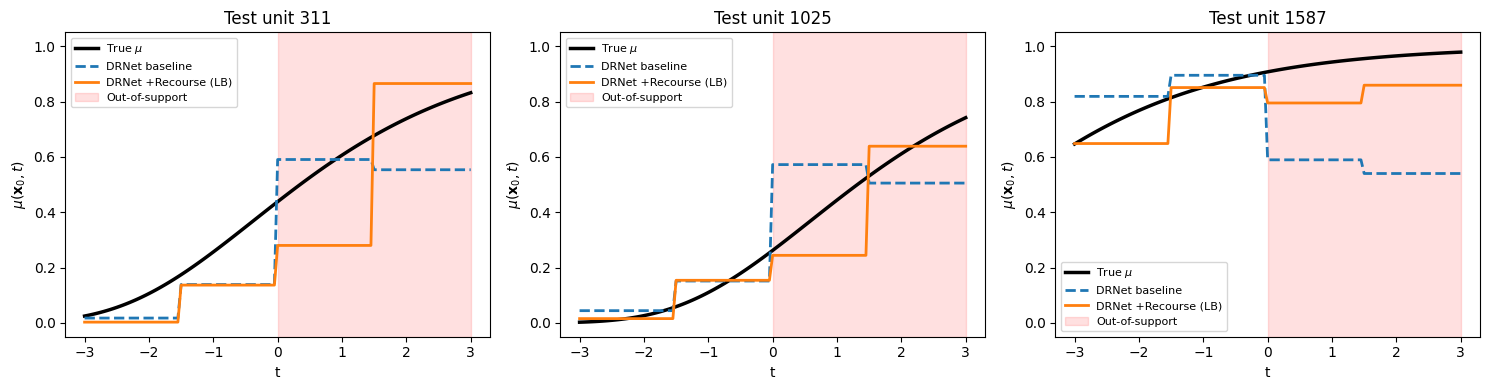

In [21]:
np.random.seed(0)
unit_idx = np.random.choice(len(test_p['X']), 3, replace=False)
t_eval = np.linspace(T_MIN, T_MAX, 121)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax_i, idx in enumerate(unit_idx):
    x0 = test_p['X'][idx:idx+1]
    x0_t = torch.from_numpy(x0).float().repeat(len(t_eval), 1)
    t_t = torch.from_numpy(t_eval.astype(np.float32))
    with torch.no_grad():
        mu_base_vals = m_base.predict_mu(x0_t, t_t).cpu().numpy()
        mu_rec_vals = m_rec.predict_mu(x0_t, t_t).cpu().numpy()
    mu_true_vals = np.array([true_mu(x0, float(t))[0] for t in t_eval])
    axes[ax_i].plot(t_eval, mu_true_vals, 'k-', lw=2.5, label='True $\\mu$')
    axes[ax_i].plot(t_eval, mu_base_vals, 'C0--', lw=2, label='DRNet baseline')
    axes[ax_i].plot(t_eval, mu_rec_vals, 'C1-', lw=2, label='DRNet +Recourse (LB)')
    axes[ax_i].axvspan(OBS_T_MAX, T_MAX, color='red', alpha=0.12, label='Out-of-support')
    axes[ax_i].set_title(f'Test unit {idx}')
    axes[ax_i].set_xlabel('t'); axes[ax_i].set_ylabel('$\\mu(\\mathbf{x}_0, t)$')
    axes[ax_i].legend(fontsize=8); axes[ax_i].set_ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

In [22]:
torch.manual_seed(0)
splits_plot = {
    'obs':     sample_dataset(N_OBS,     seed=0,    regime='obs'),
    'val':     sample_dataset(N_VAL,     seed=1000, regime='rct'),
    'rct_val': sample_dataset(N_RCT_VAL, seed=5000, regime='rct'),
    'test':    sample_dataset(N_TEST,    seed=2000, regime='rct'),
}
splits_plot, _ = standardize_X(splits_plot, fit_split='obs')
obs_p, val_p, rctv_p, test_p = splits_plot['obs'], splits_plot['val'], splits_plot['rct_val'], splits_plot['test']
Rm_p = obs_p['R'] == 1
w_lb_p = compute_lynden_bell_weights(obs_p['X'][Rm_p], obs_p['b'][Rm_p], obs_p['X'], obs_p['Y'], obs_p['T'])
w_unif_p = np.ones(Rm_p.sum())

# Two recourse-only estimators (use_obs=False): LB-weighted vs unweighted.
# Both share the same MLP architecture; the only difference is the per-unit weight.
torch.manual_seed(0)
m_lb = MLPRegressor()
m_lb, _, _ = train_model(m_lb, obs_p, val_p, rct_val=rctv_p,
                          n_epochs=N_EPOCHS, lam=1.0, weights=w_lb_p, use_obs=False)
torch.manual_seed(0)
m_unif = MLPRegressor()
m_unif, _, _ = train_model(m_unif, obs_p, val_p, rct_val=rctv_p,
                            n_epochs=N_EPOCHS, lam=1.0, weights=w_unif_p, use_obs=False)

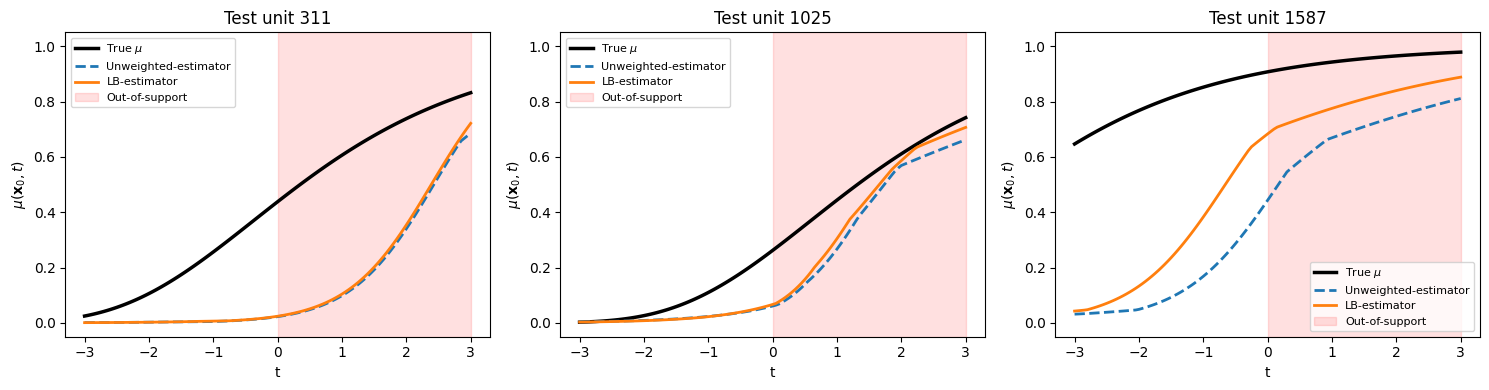

In [23]:
np.random.seed(0)
unit_idx = np.random.choice(len(test_p['X']), 3, replace=False)
t_eval = np.linspace(T_MIN, T_MAX, 121)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax_i, idx in enumerate(unit_idx):
    x0 = test_p['X'][idx:idx+1]
    x0_t = torch.from_numpy(x0).float().repeat(len(t_eval), 1)
    t_t = torch.from_numpy(t_eval.astype(np.float32))
    with torch.no_grad():
        mu_lb_vals = m_lb.predict_mu(x0_t, t_t).cpu().numpy()
        mu_unif_vals = m_unif.predict_mu(x0_t, t_t).cpu().numpy()
    mu_true_vals = np.array([true_mu(x0, float(t))[0] for t in t_eval])
    axes[ax_i].plot(t_eval, mu_true_vals, 'k-', lw=2.5, label='True $\\mu$')
    axes[ax_i].plot(t_eval, mu_unif_vals, 'C0--', lw=2, label='Unweighted-estimator')
    axes[ax_i].plot(t_eval, mu_lb_vals, 'C1-', lw=2, label='LB-estimator')
    axes[ax_i].axvspan(OBS_T_MAX, T_MAX, color='red', alpha=0.12, label='Out-of-support')
    axes[ax_i].set_title(f'Test unit {idx}')
    axes[ax_i].set_xlabel('t'); axes[ax_i].set_ylabel('$\\mu(\\mathbf{x}_0, t)$')
    axes[ax_i].legend(fontsize=8); axes[ax_i].set_ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()